# Python · Kriging with noise (`noise="nugget"`, known variances) — noisy observations

**Idea.** Kriging with noisy observations: an estimated homogeneous nugget, or known
(heteroscedastic) noise variances, must recover the noise level and predict the
noise-free function with calibrated intervals.

**Reference.** The true noise variance, replicate averaging, and the interpolating
(noise-free) fit on the same data.

**Tags.** class: Kriging · noise: none, nugget, variances ·
topic: noisy data, calibration

`Kriging` handles noisy responses through its `noise` argument: `"nugget"`
estimates one homogeneous noise variance, a vector gives a known variance per
observation (heteroscedastic case).

| case | function | noise |
|---|---|---|
| 1D homoscedastic | Forrester | N(0, 0.5²) |
| 5D homoscedastic | Friedman | N(0, 1) (the classical "Friedman 1" setup) |
| 1D heteroscedastic | Gramacy & Lee (2012) | sd growing linearly with x |
| 2D with replicates | Branin | 4 replicates of 15 points, N(0, 2²) |

Checks:
* the estimated nugget is close to the true noise variance (factor 3);
* the noisy fit predicts the noise-free function well (Q² floor), and is
  **smooth**: it does not chase the noisy data between the observations. (At the
  design points themselves the `"nugget"` predictor may return y exactly, as
  DiceKriging's nugget does: the nugget is then a micro-scale variation, and
  the predictor is discontinuous there. This is reported, not checked.);
* prediction intervals are calibrated: 95% coverage of the *noise-free* truth;
* a zero noise vector gives the noise-free model;
* with heteroscedastic noise, giving the true variances beats a single nugget
  (NLPD, warn-level);
* replicates: averaging the replicates with variance σ²/r is equivalent to
  fitting all the replicates (same predictor, up to the optimizer).

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylibkriging as lk

import gallery
from gallery import TESTS, design, metrics, compat

suite = gallery.Suite("noisy-data_Kriging-nugget-noise_python")
print("pylibkriging", compat.version())


def pred(k, X):
    m, s, *_ = k.predict(X, return_stdev=True)
    return np.ravel(m), np.ravel(s)

pylibkriging 1.2.2


## Homoscedastic noise, estimated nugget

In [3]:
for fname, n, sd, q2_floor in [("forrester", 40, 0.5, 0.95), ("friedman", 200, 1.0, 0.90)]:
    tf = TESTS[fname]
    X, y, Xt, yt = design.dataset(tf, n, n_test=2000, seed=11, noise_sd=sd)
    k = lk.Kriging(y, X, "matern5_2", noise="nugget", optim="BFGS10")
    nugget = float(np.ravel(k.nugget())[0])
    m, s = pred(k, Xt)
    res = metrics.all_metrics(yt, m, s)
    suite.metric(fname, "nugget", nugget=nugget, true_var=sd ** 2, **res)
    suite.check_between(f"{fname}: nugget / true noise variance", nugget / sd ** 2, 1 / 3, 3)
    k1 = lk.Kriging(y, X, "matern5_2", noise="nugget")   # default single start
    suite.metric(fname, "nugget, single start", nugget=float(np.ravel(k1.nugget())[0]), ll=float(k1.logLikelihood()),
                 **metrics.all_metrics(yt, *pred(k1, Xt)))
    suite.check_greater(f"{fname}: LL(single start) - LL(10 restarts)", k1.logLikelihood() - k.logLikelihood(), -1,
                  severity="warn")
    suite.check_greater(f"{fname}: Q2 vs noise-free truth", res["q2"], q2_floor)
    mX, _ = pred(k, X)
    mX_near, _ = pred(k, np.clip(X + 1e-7, 0, 1))
    suite.metric(fname, "nugget", rms_resid_at_X=metrics.rmse(y, mX) / sd,
                 rms_resid_near_X=metrics.rmse(y, mX_near) / sd)
    suite.check_greater(f"{fname}: smooths the noisy data next to the design points (rms residual / sd)",
                  metrics.rmse(y, mX_near) / sd, 0.3)
    suite.check_between(f"{fname}: coverage of the 95% intervals (noise-free truth)", res["coverage95"], 0.80, 1.0,
                  severity="warn")
    # the noise-free model on the same noisy data interpolates, and generalizes worse
    k0 = lk.Kriging(y, X, "matern5_2")
    m0, s0 = pred(k0, Xt)
    suite.metric(fname, "noise-free fit", **metrics.all_metrics(yt, m0, s0))
    suite.check_less(f"{fname}: RMSE(nugget) < RMSE(interpolating fit)", res["rmse"], metrics.rmse(yt, m0),
               severity="warn")
suite.table()

[WARN] forrester: LL(single start) - LL(10 restarts): value=-62.9975 expected > -1 


metric                             nugget  true_var      rmse        q2  \
case      package                                                         
forrester nugget                 0.176420      0.25  0.198091  0.998087   
          nugget, single start  19.629300       NaN  4.528720 -0.000031   
          noise-free fit              NaN       NaN  0.516882  0.986973   
friedman  nugget                 0.928390      1.00  0.467318  0.990891   
          nugget, single start   0.928418       NaN  0.467316  0.990891   
          noise-free fit              NaN       NaN  1.296330  0.929905   

metric                                  nlpd  coverage95      crps       ll  \
case      package                                                             
forrester nugget                2.866320e-01      1.0000  0.145679      NaN   
          nugget, single start  2.929460e+00      0.9205  2.356770 -116.318   
          noise-free fit        1.405490e+21      0.3620  0.343564      NaN   
friedman  nugget                1.070700e+00      0.9995  0.323399      NaN   
          nugget, single start  1.070700e+00      0.9995  0.323400 -345.509   
          noise-free fit        1.652850e+00      0.9215  0.707043      NaN   

metric                          rms_resid_at_X  rms_resid_near_X  
case      package                                                 
forrester nugget                  1.545410e-13          0.679911  
          nugget, single start             NaN               NaN  
          noise-free fit                   NaN               NaN  
friedman  nugget                  1.939100e-12          0.860003  
          nugget, single start             NaN               NaN  
          noise-free fit                   NaN               NaN

## A zero noise vector is the noise-free model

In [4]:
tf = TESTS["branin"]
X, y, Xt, yt = design.dataset(tf, 25, n_test=200, seed=12)
k0 = lk.Kriging(y, X, "matern5_2")
theta = np.asarray(k0.theta()).reshape(1, -1)
fixed = {"theta": theta, "is_theta_estim": False, "sigma2": float(k0.sigma2()), "is_sigma2_estim": False}
kf = lk.Kriging(y, X, "matern5_2", optim="none", parameters=fixed)
with suite.check_runs("noise=zeros, theta and sigma2 fixed: fit"):
    kz = lk.Kriging(y, X, "matern5_2", noise=np.zeros(len(y)), optim="none", parameters=fixed)
    suite.check_close("noise=zeros: same mean as the noise-free model", pred(kz, Xt)[0], pred(kf, Xt)[0], rtol=1e-6,
                atol=1e-8 * np.std(y))
    suite.check_close("noise=zeros: same stdev as the noise-free model", pred(kz, Xt)[1], pred(kf, Xt)[1], rtol=1e-4,
                atol=1e-6 * np.std(y))
with suite.check_runs("noise=zeros, sigma2 estimated: fit", severity="warn"):
    lk.Kriging(y, X, "matern5_2", noise=np.zeros(len(y)), optim="none",
               parameters={"theta": theta, "is_theta_estim": False})

[WARN] noise=zeros, sigma2 estimated: fit: value=RuntimeError expected no exception [ERROR] Exceed max numerical nugget (11 x 1e-10.000000) added to force chol matrix


## Heteroscedastic noise: known variances vs a single nugget

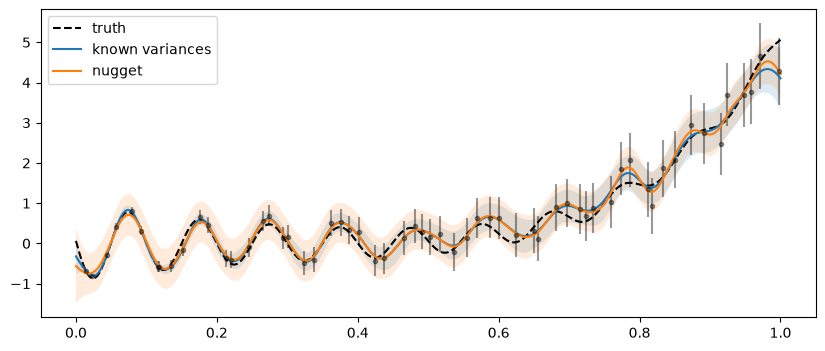

In [5]:
tf = TESTS["gramacy_lee_2012"]
n = 60
X, _, Xt, yt = design.dataset(tf, n, n_test=2000, seed=13)
sd_x = 0.02 + 0.4 * X[:, 0]  # noise sd grows with x (in unit coordinates)
y = tf.unit(X) + np.random.default_rng(13).normal(0, sd_x)
k_known = lk.Kriging(y, X, "matern5_2", noise=sd_x ** 2, optim="BFGS10")
k_nug = lk.Kriging(y, X, "matern5_2", noise="nugget", optim="BFGS10")
res_known = metrics.all_metrics(yt, *pred(k_known, Xt))
res_nug = metrics.all_metrics(yt, *pred(k_nug, Xt))
suite.metric("gramacy_lee_2012/hetero", "known variances", **res_known)
suite.metric("gramacy_lee_2012/hetero", "nugget", **res_nug)
suite.check_finite("hetero: predictions finite", pred(k_known, Xt)[0])
suite.check_less("hetero: NLPD(known variances) <= NLPD(nugget)", res_known["nlpd"] - res_nug["nlpd"], 0.05,
           severity="warn")
suite.check_close("noise(): returns the given variances", np.ravel(k_known.noise()), sd_x ** 2, rtol=1e-12)

u = np.linspace(0, 1, 400)[:, None]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(u, tf.unit(u), "k--", label="truth")
ax.errorbar(X[:, 0], y, yerr=2 * sd_x, fmt="k.", alpha=0.4)
for k, lab in [(k_known, "known variances"), (k_nug, "nugget")]:
    m, s = pred(k, u)
    ax.plot(u, m, label=lab)
    ax.fill_between(u[:, 0], m - 2 * s, m + 2 * s, alpha=0.15)
ax.legend();

## Replicates

r noisy replicates at the same point carry the same information as their mean
with variance σ²/r: fitting the replicates with `noise=σ²` or their means with
`noise=σ²/r` must give the same predictor at a fixed θ.

In [6]:
tf = TESTS["branin"]
r, sd = 4, 2.0
X1, _, Xt, yt = design.dataset(tf, 15, n_test=300, seed=14)
Xr = np.repeat(X1, r, axis=0)
yr = tf.unit(Xr) + np.random.default_rng(14).normal(0, sd, len(Xr))
ybar = yr.reshape(-1, r).mean(axis=1)
k_rep = lk.Kriging(yr, Xr, "matern5_2", noise=np.full(len(yr), sd ** 2))
fixed = {"theta": np.asarray(k_rep.theta()).reshape(1, -1), "is_theta_estim": False,
         "sigma2": float(k_rep.sigma2()), "is_sigma2_estim": False}
k_rep = lk.Kriging(yr, Xr, "matern5_2", noise=np.full(len(yr), sd ** 2), optim="none", parameters=fixed)
k_avg = lk.Kriging(ybar, X1, "matern5_2", noise=np.full(len(ybar), sd ** 2 / r), optim="none", parameters=fixed)
suite.check_close("replicates == averages with variance/r (mean)", pred(k_rep, Xt)[0], pred(k_avg, Xt)[0],
            rtol=1e-6, atol=1e-6 * np.std(yr))
suite.check_close("replicates == averages with variance/r (stdev)", pred(k_rep, Xt)[1], pred(k_avg, Xt)[1],
            rtol=1e-4, atol=1e-6 * np.std(yr))

True

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/noisy-data_Kriging-nugget-noise_python.checks.csv` and `.metrics.csv`.

In [7]:
suite.summary()

metric                                         nugget  true_var    rmse  \
case                    package                                           
forrester               nugget                 0.1764      0.25  0.1981   
                        nugget, single start  19.6293       NaN  4.5287   
                        noise-free fit            NaN       NaN  0.5169   
friedman                nugget                 0.9284      1.00  0.4673   
                        nugget, single start   0.9284       NaN  0.4673   
                        noise-free fit            NaN       NaN  1.2963   
gramacy_lee_2012/hetero nugget                    NaN       NaN  0.1709   
                        known variances           NaN       NaN  0.1687   

metric                                            q2          nlpd  \
case                    package                                      
forrester               nugget                0.9981  2.866000e-01   
                        nugget, single start -0.0000  2.929500e+00   
                        noise-free fit        0.9870  1.405490e+21   
friedman                nugget                0.9909  1.070700e+00   
                        nugget, single start  0.9909  1.070700e+00   
                        noise-free fit        0.9299  1.652800e+00   
gramacy_lee_2012/hetero nugget                0.9821 -2.216000e-01   
                        known variances       0.9825 -5.706000e-01   

metric                                        coverage95    crps       ll  \
case                    package                                             
forrester               nugget                    1.0000  0.1457      NaN   
                        nugget, single start      0.9205  2.3568 -116.318   
                        noise-free fit            0.3620  0.3436      NaN   
friedman                nugget                    0.9995  0.3234      NaN   
                        nugget, single start      0.9995  0.3234 -345.509   
                        noise-free fit            0.9215  0.7070      NaN   
gramacy_lee_2012/hetero nugget                    0.9935  0.0998      NaN   
                        known variances           0.9670  0.0865      NaN   

metric                                        rms_resid_at_X  rms_resid_near_X  
case                    package                                                 
forrester               nugget                           0.0            0.6799  
                        nugget, single start             NaN               NaN  
                        noise-free fit                   NaN               NaN  
friedman                nugget                           0.0            0.8600  
                        nugget, single start             NaN               NaN  
                        noise-free fit                   NaN               NaN  
gramacy_lee_2012/hetero nugget                           NaN               NaN  
                        known variances                  NaN               NaN

21 checks: PASS 19, FAIL 0, WARN 2, KNOWN 0, SKIP 0


,status,severity,check,value,expected,detail
0,WARN,warn,forrester: LL(single start) - LL(10 restarts),-62.9975,> -1,
1,WARN,warn,"noise=zeros, sigma2 estimated: fit",RuntimeError,no exception,[ERROR] Exceed max numerical nugget (11 x 1e-1...


In [8]:
suite.finalize()

noisy-data_Kriging-nugget-noise_python: PASS 19, FAIL 0, WARN 2, KNOWN 0, SKIP 0


{'PASS': 19, 'FAIL': 0, 'WARN': 2, 'KNOWN': 0, 'SKIP': 0}